# 01 Meet the data

Before we model anything we want to know what Walmart actually gave us. The M5 data comes as three files: daily
sales per product and store, a calendar, and weekly prices. In this notebook we open all three, look at their size,
types and gaps, and save a small snapshot of each. The next notebook uses this to decide which part of the data we
study.

## Load the three files

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from config import ROOT, RAW, FIGS
from plots import CREAM, PAPER, table_png

FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(CREAM)
written = []

sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
cal = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(RAW / "sell_prices.csv")

## Size, types and gaps

In [2]:
for name, df in [("sales", sales), ("calendar", cal), ("prices", prices)]:
    print(f"{name:9s} {df.shape[0]:>9,} rows x {df.shape[1]:>5,} columns, empty cells: {int(df.isna().sum().sum()):,}")

days = [c for c in sales.columns if c.startswith("d_")]
print(f"\nsales: {len(days)} day columns ({days[0]} to {days[-1]}) and {sales.shape[1] - len(days)} id columns")
print("sales column types:", sales.dtypes.astype(str).value_counts().to_dict())
print("calendar runs from", cal["date"].min().date(), "to", cal["date"].max().date())

sales        30,490 rows x 1,947 columns, empty cells: 0
calendar      1,969 rows x    14 columns, empty cells: 7,542
prices    6,841,121 rows x     4 columns, empty cells: 0

sales: 1941 day columns (d_1 to d_1941) and 6 id columns
sales column types: {'int64': 1941, 'str': 6}
calendar runs from 2011-01-29 to 2016-06-19


In [3]:
# the calendar has empty cells, so we check which columns they are in
print(cal.isna().sum()[cal.isna().sum() > 0])
print("\ndays with an event:", cal["event_name_1"].notna().sum(), "| days with two events:", cal["event_name_2"].notna().sum())

event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
dtype: int64

days with an event: 162 | days with two events: 5


In [4]:
# prices have no empty cells, but a row only exists once a product is on sale in that store
pairs = prices.groupby(["store_id", "item_id"]).ngroups
weeks = prices["wm_yr_wk"].nunique()
print(f"{pairs:,} store-product pairs x {weeks} weeks = {pairs * weeks:,} possible rows; {len(prices):,} exist "
      f"({len(prices) / (pairs * weeks):.1%})")
print("price range: $", prices["sell_price"].min(), "to $", prices["sell_price"].max(), "| median $", round(prices["sell_price"].median(), 2))

30,490 store-product pairs x 282 weeks = 8,598,180 possible rows; 6,841,121 exist (79.6%)
price range: $ 0.01 to $ 107.32 | median $ 3.47


In [5]:
sales.iloc[:3, :8]

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0


In [6]:
sales.iloc[-3:, list(range(6)) + list(range(-3, 0))]

,id,item_id,dept_id,cat_id,store_id,state_id,d_1939,d_1940,d_1941
30487,FOODS_3_825_WI_3_evaluation,FOODS_3_825,FOODS_3,FOODS,WI_3,WI,1,0,2
30488,FOODS_3_826_WI_3_evaluation,FOODS_3_826,FOODS_3,FOODS,WI_3,WI,1,1,0
30489,FOODS_3_827_WI_3_evaluation,FOODS_3_827,FOODS_3,FOODS,WI_3,WI,2,5,1


In [7]:
cal.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [8]:
cal.tail(3)

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
1966,2016-06-17,11620,Friday,7,6,2016,d_1967,NaN,NaN,NaN,NaN,0,0,0
1967,2016-06-18,11621,Saturday,1,6,2016,d_1968,NaN,NaN,NaN,NaN,0,0,0
1968,2016-06-19,11621,Sunday,2,6,2016,d_1969,NBAFinalsEnd,Sporting,Father's day,Cultural,0,0,0


In [9]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


## What the columns mean

| File | Column | Meaning |
|---|---|---|
| sales | `item_id`, `dept_id`, `cat_id` | product code, department (7) and category (FOODS, HOBBIES, HOUSEHOLD) |
| sales | `store_id`, `state_id` | one of 10 stores in California, Texas or Wisconsin |
| sales | `d_1` ... `d_1941` | units sold that day; this is what we forecast |
| calendar | `date`, `d` | the real date for each `d_` column |
| calendar | `wm_yr_wk`, `weekday`, `month`, `year` | Walmart week (Saturday to Friday) and calendar parts |
| calendar | `event_name_1/2`, `event_type_1/2` | holidays and events, empty on normal days |
| calendar | `snap_CA`, `snap_TX`, `snap_WI` | 1 on days when food-assistance (SNAP) benefits can be spent |
| prices | `store_id`, `item_id`, `wm_yr_wk`, `sell_price` | the price of a product in a store for one week |

## Snapshots

One image per file, and all three stacked together. The sales file has 1,941 day columns, so the picture shows
only the first and last three.

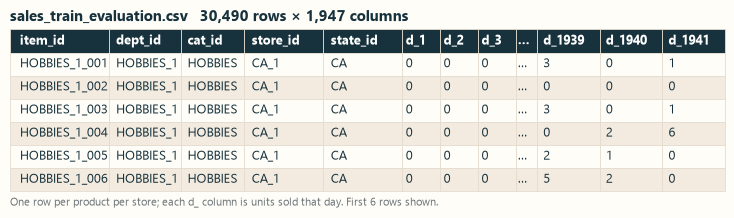

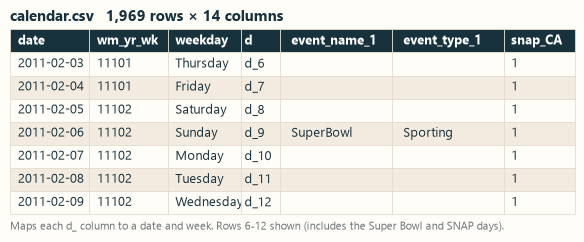

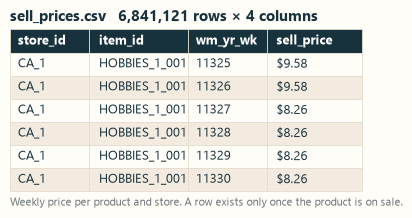

In [10]:
snap = sales[["item_id", "dept_id", "cat_id", "store_id", "state_id"] + days[:3] + days[-3:]].head(6).copy()
snap.insert(8, "…", "…")
p1 = table_png(snap, f"sales_train_evaluation.csv   {sales.shape[0]:,} rows × {sales.shape[1]:,} columns",
               FIGS / "snapshot_sales.png", "One row per product per store; each d_ column is units sold that day. First 6 rows shown.")

snap = cal[["date", "wm_yr_wk", "weekday", "d", "event_name_1", "event_type_1", "snap_CA"]].iloc[5:12].copy()
snap["date"] = snap["date"].dt.strftime("%Y-%m-%d")
p2 = table_png(snap, f"calendar.csv   {cal.shape[0]:,} rows × {cal.shape[1]} columns", FIGS / "snapshot_calendar.png",
               "Maps each d_ column to a date and week. Rows 6-12 shown (includes the Super Bowl and SNAP days).")

snap = prices.head(6).copy()
snap["sell_price"] = snap["sell_price"].map("${:.2f}".format)
p3 = table_png(snap, f"sell_prices.csv   {prices.shape[0]:,} rows × {prices.shape[1]} columns", FIGS / "snapshot_prices.png",
               "Weekly price per product and store. A row exists only once the product is on sale.")
written += [p1, p2, p3]

In [11]:
# all three stacked, for a single picture of the data
imgs = [Image.open(p).convert("RGB") for p in (p1, p2, p3)]
gap, w = 30, max(i.width for i in imgs)
both = Image.new("RGB", (w, sum(i.height for i in imgs) + gap * 2), PAPER)
y = 0
for im in imgs:
    both.paste(im, (0, y))
    y += im.height + gap
both.save(FIGS / "snapshot_all_files.png")
written.append(FIGS / "snapshot_all_files.png")

## What we found

The sales file is 30,490 rows by 1,947 columns: 6 id columns and one column per day for 1,941 days, from
29 January 2011 to 22 May 2016. It has no empty cells at all. The calendar runs 28 days longer, to 19 June 2016,
because the competition kept the last four weeks hidden; we never use those days.

The 7,542 empty cells in the calendar are not a problem. They sit in the event columns, which are simply empty on
the 1,807 normal days. Only 162 days have an event, and 5 have two.

Prices were the surprise. There are no empty cells, but only 79.6% of the possible store-product-week rows exist.
A product has no price row until it goes on sale in that store. That turns out to matter: in the sales file those
missing weeks show up as zero sales, which looks like demand but is not. Notebook 04 deals with it.

## What comes next

In `02_scope` we narrow the data to California and pick the products we will study.

In [12]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\figures\snapshot_sales.png 96 KB
outputs\figures\snapshot_calendar.png 78 KB
outputs\figures\snapshot_prices.png 62 KB
outputs\figures\snapshot_all_files.png 246 KB
